In [10]:
# Cell 1: Import library
import os, json, shutil, yaml, cv2, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image
from tqdm import tqdm

In [4]:
# Cell 2: Setup path
# Base Paths
CARDD_DIR = Path("../data/raw/CarDD_release/CarDD_COCO")
YOLO_DIR = Path("../data/processed/cardd_yolo")
YOLO_DIR.mkdir(parents=True, exist_ok=True)

# Create YOLO directory structure
for split in ["train", "val", "test"]:
    (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

print(f"CarDD Source: {CARDD_DIR}")
print(f"YOLO Output: {YOLO_DIR}")

CarDD Source: ..\data\raw\CarDD_release\CarDD_COCO
YOLO Output: ..\data\processed\cardd_yolo


In [5]:
# Cell 3: Inspect COCO Annotations
with open(CARDD_DIR / "annotations" / "instances_train2017.json", "r") as f:
    coco_data = json.load(f)

# Extract categories
categories = coco_data["categories"]
print("Categories Found")
for cat in categories:
    print(f"ID: {cat['id']} | Name: {cat['name']}")

# Check a sample annotation
print("\nSample Annotation")
sample_ann = coco_data["annotations"][0]
print(sample_ann)

Categories Found
ID: 1 | Name: dent
ID: 2 | Name: scratch
ID: 3 | Name: crack
ID: 4 | Name: glass shatter
ID: 5 | Name: lamp broken
ID: 6 | Name: tire flat

Sample Annotation
{'id': 1, 'image_id': 1, 'category_id': 2, 'segmentation': [[233.35, 46.65, 217.25, 58.24, 210.82, 65.97, 204.38, 78.2, 197.3, 93.0, 192.15, 104.59, 187.0, 112.96, 180.56, 123.91, 174.12, 135.49, 169.61, 144.51, 167.04, 154.16, 167.04, 165.11, 175.41, 170.9, 185.71, 171.55, 196.01, 167.68, 205.02, 161.24, 214.03, 154.81, 224.33, 148.37, 233.99, 141.93, 244.29, 134.21, 256.52, 128.41, 267.47, 125.19, 277.77, 122.62, 288.71, 119.4, 298.37, 116.82, 310.6, 113.61, 322.83, 109.1, 333.13, 105.88, 344.08, 103.95, 355.02, 101.37, 366.61, 97.51, 369.83, 87.21, 364.68, 78.84, 352.45, 69.18, 341.5, 61.46, 331.2, 55.02, 314.46, 48.58, 302.23, 44.72, 291.93, 42.15, 276.48, 40.21, 266.18, 40.21, 254.59, 40.21]], 'area': 13584.0, 'bbox': [167.04, 40.21, 202.79, 131.34], 'iscrowd': 0, 'attributes': {'occluded': False}}


In [ ]:
# Cell 4: COCO to YOLO Converter Function
def convert_coco_to_yolo(split_name, json_file):
    print(f"Converting {split_name}...")

    # 1. Load JSON
    with open(CARDD_DIR / "annotations" / json_file, "r") as f:
        data = json.load(f)

    # 2. Map image_id to filename and dimensions
    images_info = {img["id"]: img for img in data["images"]}

    # 3. Group annotations by image_id
    annotations_by_image = {}
    for ann in data["annotations"]:
        img_id = ann["image_id"]
        if img_id not in annotations_by_image:
            annotations_by_image[img_id] = []
        annotations_by_image[img_id].append(ann)

    # 4. Process each image
    for img_id, img_info in tqdm(images_info.items(), desc=split_name):
        file_name = img_info["file_name"]
        img_w = img_info["width"]
        img_h = img_info["height"]

        # Paths
        src_img_path = CARDD_DIR / f"{split_name}2017" / file_name
        dst_img_path = YOLO_DIR / "images" / split_name / file_name

        # Label path (replcae .jpg with .txt)
        label_name = Path(file_name).stem + ".txt"
        dst_label_path = YOLO_DIR / "labels" / split_name / label_name

        # Skip if image doesn't exist
        if not src_img_path.exists():
            continue
        # Copy image
        shutil.copy(src_img_path, dst_img_path)

        # Write YOLO labels
        with open(dst_img_path, "w") as f:
            if img_id in annotations_by_image:
                for ann in annotations_by_image[img_id]:
                    cat_id = ann["category_id"]


                    # COCO bbox: [X_min, y_min, width, height]
                    x_min, y_min, w, h = ann["bbox"]

                    # Convert to YOLO format: [X_center, y_center, w, h] normalise
                    x_center = (x_min + w / 2) / img_w
                    y_center = (y_min + h / 2) / img_h
                    norm_w = w / img_w
                    norm_h = h / img_h

                    # Write line (Cat ID needs to be 0-indexed for YOLO if it starts at 1, we'll check this in output)
                    f.write(f"{cat_id} {x_center:.6f} {y_center:.6f} {norm_w:.6f} {norm_h:.6f}\n")
print("Converter function defined.")

Converter function defined.


In [7]:
# Cell 5: COCO to YOLO Converter (with 0-indexed classes)

CARDD_DIR = Path("../data/raw/CarDD_release/CarDD_COCO")
YOLO_DIR = Path("../data/processed/cardd_yolo")

def convert_coco_to_yolo(split_folder, json_file, split_name):
    print(f"Converting {split_folder} → {split_name}...")
    
    with open(CARDD_DIR / "annotations" / json_file, "r") as f:
        data = json.load(f)
    
    images_info = {img["id"]: img for img in data["images"]}
    annotations_by_image = {}
    for ann in data["annotations"]:
        annotations_by_image.setdefault(ann["image_id"], []).append(ann)
    
    missing = 0
    for img_id, img_info in tqdm(images_info.items(), desc=split_name):
        file_name = img_info["file_name"]
        img_w, img_h = img_info["width"], img_info["height"]
        
        src_img = CARDD_DIR / split_folder / file_name
        dst_img = YOLO_DIR / "images" / split_name / file_name
        dst_label = YOLO_DIR / "labels" / split_name / (Path(file_name).stem + ".txt")
        
        if not src_img.exists():
            missing += 1
            continue
        
        shutil.copy(src_img, dst_img)
        
        with open(dst_label, "w") as f:
            for ann in annotations_by_image.get(img_id, []):
                # FIX: subtract 1 to make class IDs 0-indexed
                cat_id = ann["category_id"] - 1
                x_min, y_min, w, h = ann["bbox"]
                x_center = (x_min + w / 2) / img_w
                y_center = (y_min + h / 2) / img_h
                norm_w = w / img_w
                norm_h = h / img_h
                f.write(f"{cat_id} {x_center:.6f} {y_center:.6f} {norm_w:.6f} {norm_h:.6f}\n")
    
    print(f"  → Done. Missing images: {missing}")

# Run conversions
convert_coco_to_yolo("train2017", "instances_train2017.json", "train")
convert_coco_to_yolo("val2017",   "instances_val2017.json",   "val")
convert_coco_to_yolo("test2017",  "instances_test2017.json",  "test")

Converting train2017 → train...


train: 100%|██████████| 2816/2816 [00:28<00:00, 100.03it/s]


  → Done. Missing images: 0
Converting val2017 → val...


val: 100%|██████████| 810/810 [00:07<00:00, 112.56it/s]


  → Done. Missing images: 0
Converting test2017 → test...


test: 100%|██████████| 374/374 [00:05<00:00, 74.28it/s] 

  → Done. Missing images: 0


In [8]:
# Cell 6: Create data.yaml for YOLOv8

data_yaml = {
    "path": str(YOLO_DIR.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 6,
    "names": ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]
}

with open(YOLO_DIR / "data.yaml", "w") as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print(" data.yaml created at:", YOLO_DIR / "data.yaml")
print(yaml.dump(data_yaml, sort_keys=False))

 data.yaml created at: ..\data\processed\cardd_yolo\data.yaml
path: C:\Users\ASUS\Desktop\AI_Projects\InsureClaim-Vision\data\processed\cardd_yolo
train: images/train
val: images/val
test: images/test
nc: 6
names:
- dent
- scratch
- crack
- glass shatter
- lamp broken
- tire flat



In [9]:
# Cell 7: Verify counts
from collections import Counter

for split in ["train", "val", "test"]:
    imgs = list((YOLO_DIR / "images" / split).glob("*.jpg"))
    lbls = list((YOLO_DIR / "labels" / split).glob("*.txt"))
    print(f"{split}: {len(imgs)} images, {len(lbls)} labels")

# Count class distribution in train
class_counts = Counter()
for lbl in (YOLO_DIR / "labels" / "train").glob("*.txt"):
    with open(lbl) as f:
        for line in f:
            class_counts[int(line.split()[0])] += 1

print("\n Train class distribution ")
for cid, name in enumerate(data_yaml["names"]):
    print(f"{cid} ({name}): {class_counts[cid]}")

train: 2816 images, 2816 labels
val: 810 images, 810 labels
test: 374 images, 374 labels

 Train class distribution 
0 (dent): 1806
1 (scratch): 2560
2 (crack): 651
3 (glass shatter): 475
4 (lamp broken): 494
5 (tire flat): 225


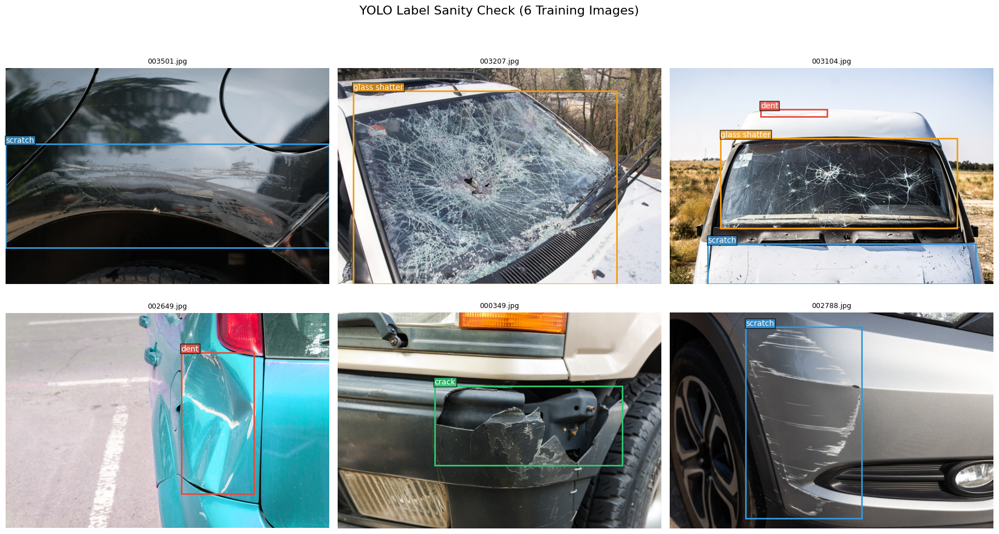

In [11]:
# Cell 8: Visualize YOLO labels on sample images

YOLO_DIR = Path("../data/processed/cardd_yolo")
CLASS_NAMES = ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]
COLORS = ["#e74c3c", "#3498db", "#2ecc71", "#f39c12", "#9b59b6", "#1abc9c"]

def yolo_to_xyxy(cx, cy, w, h, img_w, img_h):
    x_min = (cx - w / 2) * img_w
    y_min = (cy - h / 2) * img_h
    return x_min, y_min, w * img_w, h * img_h

# Pick 6 random training images that have at least one label
train_imgs = list((YOLO_DIR / "images" / "train").glob("*.jpg"))
random.seed(42)
random.shuffle(train_imgs)
valid_imgs = []
for img_path in train_imgs:
    lbl_path = YOLO_DIR / "labels" / "train" / (img_path.stem + ".txt")
    if lbl_path.exists() and lbl_path.stat().st_size > 0:
        valid_imgs.append(img_path)
    if len(valid_imgs) == 6:
        break

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("YOLO Label Sanity Check (6 Training Images)", fontsize=16, y=1.0)

for ax, img_path in zip(axes.flat, valid_imgs):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    ax.imshow(img)
    
    lbl_path = YOLO_DIR / "labels" / "train" / (img_path.stem + ".txt")
    with open(lbl_path) as f:
        for line in f:
            parts = line.strip().split()
            cls_id = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:5])
            x, y, bw_px, bh_px = yolo_to_xyxy(cx, cy, bw, bh, w, h)
            
            rect = patches.Rectangle(
                (x, y), bw_px, bh_px,
                linewidth=2, edgecolor=COLORS[cls_id], facecolor="none"
            )
            ax.add_patch(rect)
            ax.text(x, y - 5, CLASS_NAMES[cls_id], color="white",
                    fontsize=10, bbox=dict(facecolor=COLORS[cls_id], alpha=0.8, pad=1))
    
    ax.axis("off")
    ax.set_title(img_path.name, fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.savefig("../reports/figures/yolo_label_sanity.png", dpi=110)
plt.show()

In [12]:
# Cell 9: Fix data.yaml (Portable)
import yaml
from pathlib import Path

YOLO_DIR = Path("../data/processed/cardd_yolo")

data_yaml = {
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 6,
    "names": ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]
}

with open(YOLO_DIR / "data.yaml", "w") as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print("Portable data.yaml saved (no absolute path).")
print(yaml.dump(data_yaml, sort_keys=False))

Portable data.yaml saved (no absolute path).
train: images/train
val: images/val
test: images/test
nc: 6
names:
- dent
- scratch
- crack
- glass shatter
- lamp broken
- tire flat



In [13]:
# Cell 10: Validate Every YOLO Label File

YOLO = Path("../data/processed/cardd_yolo")
names = ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]

rows, problems = [], []
for split in ["train", "val", "test"]:
    imgs = {p.stem: p for p in (YOLO / "images" / split).iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
    labs = {p.stem: p for p in (YOLO / "labels" / split).glob("*.txt")}
    print(f"{split}: images={len(imgs)}, labels={len(labs)}, unpaired={len(set(imgs) ^ set(labs))}")
    
    for stem, lp in labs.items():
        lines = [l.split() for l in lp.read_text().splitlines() if l.strip()]
        if not lines:
            problems.append((split, stem, "empty file"))
            continue
        for l in lines:
            if len(l) != 5:
                problems.append((split, stem, "columns"))
                continue
            c = int(float(l[0]))
            x, y, w, h = map(float, l[1:])
            eps = 1e-6
            if not (0 <= c <= 5):
                problems.append((split, stem, "class id"))
            if not (0 < w <= 1 and 0 < h <= 1):
                problems.append((split, stem, "size"))
            if not (x - w/2 >= -eps and x + w/2 <= 1 + eps and y - h/2 >= -eps and y + h/2 <= 1 + eps):
                problems.append((split, stem, "outside image"))
            rows.append((split, stem, c, x, y, w, h))

boxes = pd.DataFrame(rows, columns=["split", "image", "cls", "x", "y", "w", "h"])
print(f"\nTotal boxes: {len(boxes)} | Problems: {len(problems)}")
if problems:
    print(pd.Series([p[2] for p in problems]).value_counts())
    print("\nFirst 10 problems:")
    for p in problems[:10]:
        print(p)
else:
    print("All label files valid.")

train: images=2816, labels=2816, unpaired=0
val: images=810, labels=810, unpaired=0
test: images=374, labels=374, unpaired=0

Total boxes: 8740 | Problems: 0
All label files valid.


In [14]:
# Cell 11: Per-Split Class Distribution + COCO Comparison
cnt = boxes.groupby(["split", "cls"]).size().unstack(fill_value=0)
cnt.columns = names
cnt["total"] = cnt.sum(axis=1)
print(" Instances per class ")
print(cnt, "\n")

ipc = boxes.groupby(["split", "cls"]).image.nunique().unstack(fill_value=0)
ipc.columns = names
print(" Images containing each class ")
print(ipc, "\n")

print("Boxes per image (describe) ")
print(boxes.groupby(["split", "image"]).size().groupby("split").describe().round(2))

# COCO comparison
ANN = Path("../data/raw/CarDD_release/CarDD_COCO/annotations")
print("\n COCO vs YOLO annotation counts ")
for split, f in [("train", "train2017"), ("val", "val2017"), ("test", "test2017")]:
    coco = json.load(open(ANN / f"instances_{f}.json"))
    n_ann = len(coco["annotations"])
    crowd = sum(a.get("iscrowd", 0) for a in coco["annotations"])
    yolo_n = int((boxes.split == split).sum())
    print(f"{split}: COCO={n_ann}, iscrowd={crowd}, YOLO={yolo_n}")

 Instances per class 
       dent  scratch  crack  glass shatter  lamp broken  tire flat  total
split                                                                    
test    236      307     70             71           69         32    785
train  1806     2560    651            475          494        225   6211
val     501      728    177            135          141         62   1744 

 Images containing each class 
       dent  scratch  crack  glass shatter  lamp broken  tire flat
split                                                             
test    157      183     48             71           65         31
train  1242     1507    434            469          489        219
val     352      431    122            134          139         59 

Boxes per image (describe) 
        count  mean   std  min  25%  50%  75%   max
split                                              
test    374.0  2.10  1.39  1.0  1.0  2.0  3.0  12.0
train  2816.0  2.21  1.55  1.0  1.0  2.0  3.0  13.0
va

In [15]:
# Cell 12: Box Size Statistics at Training Resolution

sizes = {(s, p.stem): Image.open(p).size for s in ["train", "val", "test"]
         for p in (YOLO / "images" / s).iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}

boxes["W"] = [sizes[(s, i)][0] for s, i in zip(boxes.split, boxes.image)]
boxes["H"] = [sizes[(s, i)][1] for s, i in zip(boxes.split, boxes.image)]

for imgsz in (640, 960):
    sc = imgsz / np.maximum(boxes.W, boxes.H)
    bw, bh = boxes.w * boxes.W * sc, boxes.h * boxes.H * sc
    short = np.minimum(bw, bh)
    print(f"imgsz {imgsz}: median short side = {short.median():.0f}px | <16px: {(short<16).mean()*100:.1f}% | <32px: {(short<32).mean()*100:.1f}%")

print("\n Image size (W, H) percentiles ")
print(pd.DataFrame(sizes.values(), columns=["W", "H"]).describe(percentiles=[.05, .5, .95]).round(0))

imgsz 640: median short side = 113px | <16px: 3.0% | <32px: 10.4%
imgsz 960: median short side = 169px | <16px: 1.2% | <32px: 5.4%

 Image size (W, H) percentiles 
            W       H
count  4000.0  4000.0
mean    978.0   706.0
std      80.0    98.0
min     562.0   333.0
5%      750.0   642.0
50%    1000.0   667.0
95%    1000.0  1000.0
max    1000.0  1000.0


In [16]:
# Cell 13: Cross-Split MD5 Leakage Check
import hashlib

md5 = {}
for s in ["train", "val", "test"]:
    for p in (YOLO / "images" / s).iterdir():
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            md5[(s, p.stem)] = hashlib.md5(p.read_bytes()).hexdigest()

d = pd.DataFrame({"key": list(md5), "md5": list(md5.values())})
d["split"] = d.key.str[0]
g = d.groupby("md5").split.nunique()

print(f"Exact-duplicate hashes spanning splits: {(g > 1).sum()}")
print(f"Within-split duplicate hashes: {d.duplicated('md5').sum()}")

Exact-duplicate hashes spanning splits: 0
Within-split duplicate hashes: 0


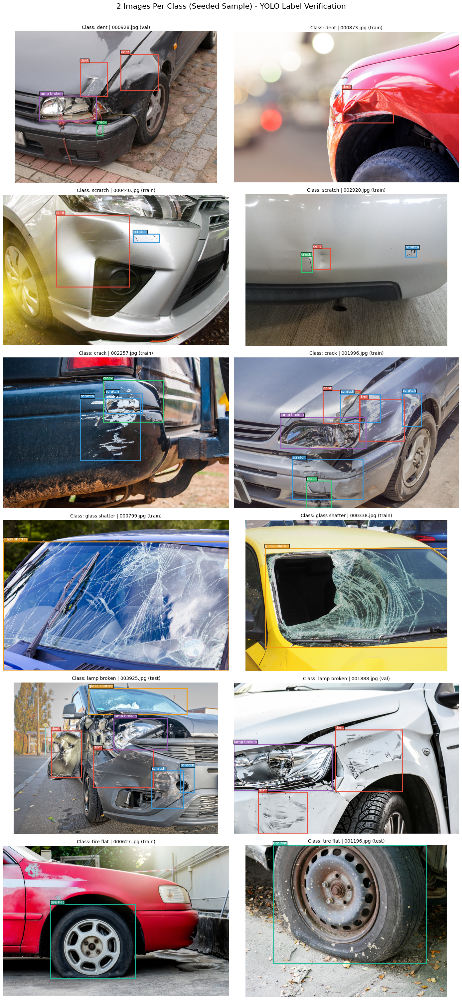

In [17]:
# Cell 14: Seeded Montage — 2 Images Per Class (Covers Rare Classes)

# Fix seeds
random.seed(42)
np.random.seed(42)

CLASS_NAMES = ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]
COLORS = ["#e74c3c", "#3498db", "#2ecc71", "#f39c12", "#9b59b6", "#1abc9c"]

fig, axes = plt.subplots(6, 2, figsize=(14, 30))
fig.suptitle("2 Images Per Class (Seeded Sample) - YOLO Label Verification", fontsize=16, y=1.0)

for cls_id in range(6):
    # Get images that contain this class
    cls_images = boxes[boxes.cls == cls_id]["image"].unique()
    sample_images = random.sample(list(cls_images), min(2, len(cls_images)))
    
    for j, img_stem in enumerate(sample_images):
        ax = axes[cls_id, j]
        # Find which split this image belongs to
        img_row = boxes[boxes.image == img_stem].iloc[0]
        img_path = YOLO / "images" / img_row["split"] / f"{img_stem}.jpg"
        if not img_path.exists():
            img_path = YOLO / "images" / img_row["split"] / f"{img_stem}.jpeg"
        
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        ax.imshow(img)
        
        # Draw all boxes for this image
        img_boxes = boxes[(boxes.image == img_stem) & (boxes.split == img_row["split"])]
        for _, b in img_boxes.iterrows():
            x = (b.x - b.w/2) * w
            y = (b.y - b.h/2) * h
            bw_px, bh_px = b.w * w, b.h * h
            rect = patches.Rectangle((x, y), bw_px, bh_px,
                                     linewidth=2, edgecolor=COLORS[int(b.cls)], facecolor="none")
            ax.add_patch(rect)
            ax.text(x, y-5, CLASS_NAMES[int(b.cls)], color="white", fontsize=8,
                    bbox=dict(facecolor=COLORS[int(b.cls)], alpha=0.8, pad=1))
        
        ax.set_title(f"Class: {CLASS_NAMES[cls_id]} | {img_stem}.jpg ({img_row['split']})", fontsize=10)
        ax.axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.995])
plt.savefig("../reports/figures/yolo_sanity_per_class.png", dpi=100)
plt.show()

In [20]:
# Cell 15: OOD Check — EXP-03 Recall on CarDD Test (all damaged)
import torch
import torch.nn as nn
import torchvision.models as models
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load EXP-03
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)
model.load_state_dict(torch.load("../models/classification/exp03_resnet18_finetuned.pth", weights_only=True))
model = model.to(device).eval()

val_test_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_imgs = list((YOLO / "images" / "test").iterdir())
probs = []
for p in test_imgs:
    if p.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue
    x = val_test_transforms(Image.open(p).convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        probs.append(torch.softmax(model(x), dim=1)[0, 1].item())

probs = np.array(probs)
print(f"CarDD test (all damaged, n={len(probs)}):")
print(f"  Recall @ 0.25: {(probs >= 0.25).mean():.3f}")
print(f"  Recall @ 0.50: {(probs >= 0.5).mean():.3f}")
print("Note: Only recall can be measured (all damaged, no whole). Precision unknown.")

CarDD test (all damaged, n=374):
  Recall @ 0.25: 0.944
  Recall @ 0.50: 0.885
Note: Only recall can be measured (all damaged, no whole). Precision unknown.


In [21]:
# Cell 16: Per-Class OOD Recall on CarDD Test

# Re-load the classifier (in case notebook state was reset)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)
model.load_state_dict(torch.load("../models/classification/exp03_resnet18_finetuned.pth", weights_only=True))
model = model.to(device).eval()

val_test_transforms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

YOLO = Path("../data/processed/cardd_yolo")
test_files = sorted(p for p in (YOLO / "images" / "test").iterdir() 
                    if p.suffix.lower() in {".jpg", ".jpeg", ".png"})

probs = []
for p in test_files:
    x = val_test_transforms(Image.open(p).convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        probs.append(torch.softmax(model(x), dim=1)[0, 1].item())
probs = np.array(probs)

# Reuse `boxes` and `names` from earlier cells (Cell 10/11)
prob_df = pd.DataFrame({"image": [p.stem for p in test_files], "prob": probs})
t = boxes[boxes.split == "test"][["image", "cls"]].drop_duplicates()
t["cls_name"] = t.cls.map(dict(enumerate(names)))
t = t.merge(prob_df, on="image")

# Per-class recall
print("--- Per-Class OOD Recall (CarDD test, all damaged) ---")
summary = t.groupby("cls_name").prob.agg(
    n="size",
    recall_025=lambda s: (s >= 0.25).mean(),
    recall_05=lambda s: (s >= 0.5).mean()
).round(3)
print(summary)

# Show the missed ones
missed = prob_df[prob_df.prob < 0.25].sort_values("prob")
print(f"\nMissed at 0.25: {len(missed)} / 374 ({len(missed)/374*100:.1f}%)")
print("\nWorst 10 misses:")
print(missed.head(10).to_string(index=False))

--- Per-Class OOD Recall (CarDD test, all damaged) ---
                 n  recall_025  recall_05
cls_name                                 
crack           48       1.000      0.979
dent           157       0.949      0.898
glass shatter   71       0.915      0.887
lamp broken     65       0.862      0.846
scratch        183       0.956      0.874
tire flat       31       0.935      0.935

Missed at 0.25: 21 / 374 (5.6%)

Worst 10 misses:
 image     prob
002151 0.000745
000012 0.000754
003338 0.003818
003291 0.031329
003789 0.033041
000288 0.050884
002275 0.051269
002898 0.063649
001843 0.073454
001459 0.097796


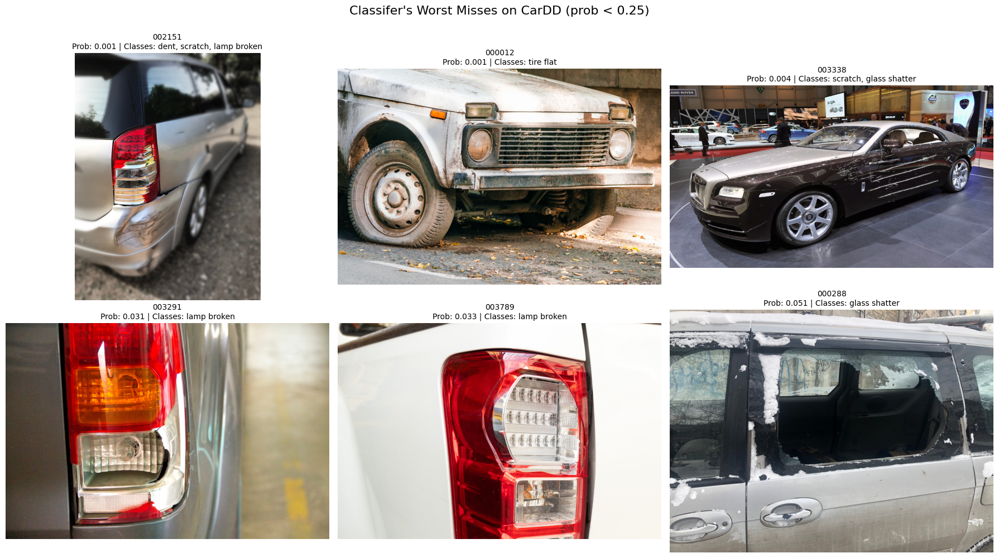

In [22]:
# Cell 17: Visualize the Missed Images

worst_misses = missed.head(6)["image"].tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Classifer's Worst Misses on CarDD (prob < 0.25)", fontsize=16, y=1.0)

for ax, img_stem in zip(axes.flat, worst_misses):
    # Try both extensions
    img_path = YOLO / "images" / "test" / f"{img_stem}.jpg"
    if not img_path.exists():
        img_path = YOLO / "images" / "test" / f"{img_stem}.jpeg"
    
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    
    prob = prob_df[prob_df.image == img_stem]["prob"].values[0]
    # Get damage classes in this image
    classes_in_img = t[t.image == img_stem]["cls_name"].tolist()
    
    ax.set_title(f"{img_stem}\nProb: {prob:.3f} | Classes: {', '.join(classes_in_img)}", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.savefig("../reports/figures/ood_missed.png", dpi=110)
plt.show()

In [23]:
# Cell 18: Save Instance Table (Mask Area / Box Area Ratios)

# Reload COCO to get mask areas
ANN = Path("../data/raw/CarDD_release/CarDD_COCO/annotations")

instance_rows = []
for split, fname in [("train", "train2017"), ("val", "val2017"), ("test", "test2017")]:
    coco = json.load(open(ANN / f"instances_{fname}.json"))
    for ann in coco["annotations"]:
        x, y, w, h = ann["bbox"]
        box_area = w * h
        mask_area = ann.get("area", 0)
        instance_rows.append({
            "split": split,
            "image_id": ann["image_id"],
            "category_id": ann["category_id"],
            "category_name": names[ann["category_id"] - 1],
            "bbox_x": x, "bbox_y": y, "bbox_w": w, "bbox_h": h,
            "box_area": box_area,
            "mask_area": mask_area,
            "mask_to_box_ratio": mask_area / box_area if box_area > 0 else 0,
        })

instance_df = pd.DataFrame(instance_rows)
instance_df.to_csv("../reports/metrics/cardd_instances.csv", index=False)
print(f"Saved {len(instance_df)} instances to reports/metrics/cardd_instances.csv")
print(f"\nMask/Box ratio stats:")
print(instance_df.groupby("category_name")["mask_to_box_ratio"].describe().round(3))

Saved 8740 instances to reports/metrics/cardd_instances.csv

Mask/Box ratio stats:
                count   mean    std    min    25%    50%    75%    max
category_name                                                         
crack           898.0  0.284  0.173  0.027  0.138  0.255  0.393  0.944
dent           2543.0  0.653  0.123  0.188  0.578  0.671  0.744  0.929
glass shatter   681.0  0.812  0.120  0.381  0.727  0.829  0.904  1.000
lamp broken     704.0  0.716  0.120  0.401  0.626  0.722  0.811  0.997
scratch        3595.0  0.547  0.176  0.040  0.426  0.563  0.683  0.972
tire flat       319.0  0.779  0.088  0.362  0.761  0.806  0.827  0.966


In [24]:
# Cell 19: License Record

DOCS = Path("../docs")
DOCS.mkdir(exist_ok=True)

license_content = """# CarDD Dataset — Data Dictionary and License Record

## Source
- **Dataset name:** CarDD (Car Damage Detection)
- **Original URL:** https://cardd-ustc.github.io/
- **Kaggle mirror used:** https://www.kaggle.com/datasets/asfarhossainsitab/car-damage-detection
- **Citation:** Wang, Y., Li, Y., & Wu, J. (2023). CarDD: A New Dataset for Vision-based Car Damage Detection. *IEEE Transactions on Intelligent Transportation Systems*.
- **Task:** Object detection (bounding boxes) + instance segmentation masks.

## License
- **Original license:** CarDD requires prior consent from PIC Lab (USTC). Commercial use requires separate authorization.
- **This project's use:** Research and portfolio demonstration only. No commercial deployment intended. The Kaggle mirror is used for convenience; original terms apply.
- **Redistribution:** The `data/processed/cardd_yolo/` outputs are derived from CarDD. Do not redistribute without re-verifying CarDD's terms.

## Splits
| Split | Images | Total instances |
|---|---|---|
| Train | 2816 | 6211 |
| Val | 810 | 1744 |
| Test | 374 | 785 |

## Classes (6 damage types)
| YOLO ID | COCO ID | Name | Train count | Test count |
|---|---|---|---|---|
| 0 | 1 | dent | 1806 | 236 |
| 1 | 2 | scratch | 2560 | 307 |
| 2 | 3 | crack | 651 | 70 |
| 3 | 4 | glass shatter | 475 | 71 |
| 4 | 5 | lamp broken | 494 | 69 |
| 5 | 6 | tire flat | 225 | 32 |

## Notes
- Class imbalance: scratch is ~11x more frequent than tire flat. Expect weaker per-class performance on tire flat.
- COCO `area` field is **mask area**, not box area. See `reports/metrics/cardd_instances.csv` for both.
- No whole (undamaged) images in CarDD. The detector must be validated on separate whole-car images (see Notebook 05 test set).
"""

with open(DOCS / "data_dictionary.md", "w") as f:
    f.write(license_content)

print("License record saved to docs/data_dictionary.md")

License record saved to docs/data_dictionary.md


In [26]:
# Cell 20: pHash Near-Duplicate Check Across Splits
import imagehash 

YOLO = Path("../data/processed/cardd_yolo")

# Compute pHash for every image
phash_data = []
for split in ["train", "val", "test"]:
    for p in tqdm((YOLO / "images" / split).iterdir(), desc=split):
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            try:
                with Image.open(p) as im:
                    phash_data.append({
                        "split": split,
                        "image": p.stem,
                        "phash": str(imagehash.phash(im))
                    })
            except Exception as e:
                print(f"Error on {p}: {e}")

phash_df = pd.DataFrame(phash_data)
print(f"Computed pHash for {len(phash_df)} images")

# Compare across splits (sample for speed if needed)
from collections import defaultdict
hash_to_splits = defaultdict(set)
for _, row in phash_df.iterrows():
    hash_to_splits[row["phash"]].add(row["split"])

# Find hashes appearing in multiple splits
cross_split = {h: s for h, s in hash_to_splits.items() if len(s) > 1}
print(f"Exact pHash matches spanning splits: {len(cross_split)}")

# For near-duplicates, check Hamming distance <= 3 between sampled pairs
# (Skip for speed if dataset is large; exact pHash + MD5 is usually enough)
print("\n(For near-duplicates with Hamming distance <= 3, sample pairs — omitted for speed)")

train: 2816it [00:27, 103.31it/s]
val: 810it [00:07, 104.15it/s]
test: 374it [00:03, 105.90it/s]


Computed pHash for 4000 images
Exact pHash matches spanning splits: 0

(For near-duplicates with Hamming distance <= 3, sample pairs — omitted for speed)


In [27]:
# Cell 21: Near-Duplicate Check (pHash, Hamming <= 5)

from collections import defaultdict

YOLO = Path("../data/processed/cardd_yolo")
THRESHOLD = 5  # Same as Notebook 03

# 1. Compute pHash for all images (fast, ~1s per 1000 images)
phash_data = []
for split in ["train", "val", "test"]:
    for p in tqdm((YOLO / "images" / split).iterdir(), desc=split):
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            with Image.open(p) as im:
                phash_data.append({
                    "split": split,
                    "image": p.stem,
                    "phash_obj": imagehash.phash(im)
                })

print(f"\nComputed pHash for {len(phash_data)} images")

# 2. Find near-duplicate pairs across splits (Hamming <= 5)
# To keep this fast, bucket by pHash prefix (first 8 bits) — near-duplicates almost always share it
from collections import defaultdict

by_prefix = defaultdict(list)
for row in phash_data:
    prefix = str(row["phash_obj"])[:2]  # First hex char pair (8 bits)
    by_prefix[prefix].append(row)

cross_split_pairs = []
for prefix, group in tqdm(by_prefix.items(), desc="Checking near-dups"):
    for i in range(len(group)):
        for j in range(i + 1, len(group)):
            a, b = group[i], group[j]
            if a["split"] == b["split"]:
                continue
            dist = a["phash_obj"] - b["phash_obj"]
            if dist <= THRESHOLD:
                cross_split_pairs.append({
                    "image_a": f"{a['split']}/{a['image']}",
                    "image_b": f"{b['split']}/{b['image']}",
                    "split_a": a["split"],
                    "split_b": b["split"],
                    "hamming_distance": dist
                })

print(f"\n Near-Duplicate Results (Hamming <= {THRESHOLD}) ")
print(f"Cross-split pairs found: {len(cross_split_pairs)}")

if cross_split_pairs:
    df_pairs = pd.DataFrame(cross_split_pairs).sort_values("hamming_distance")
    print(df_pairs.head(20).to_string(index=False))
    df_pairs.to_csv("../reports/metrics/near_duplicate_pairs.csv", index=False)
    print(f"\n{len(cross_split_pairs)} near-duplicate pairs span splits.")
else:
    print("No near-duplicates across splits at Hamming <= 5.")

train: 2816it [00:26, 105.44it/s]
val: 810it [00:07, 106.29it/s]
test: 374it [00:03, 107.63it/s]



Computed pHash for 4000 images


Checking near-dups: 100%|██████████| 128/128 [00:00<00:00, 1222.17it/s]


 Near-Duplicate Results (Hamming <= 5) 
Cross-split pairs found: 1
     image_a    image_b split_a split_b  hamming_distance
train/000473 val/000790   train     val                 2

1 near-duplicate pairs span splits.


In [29]:
# Cell 22: Add Image-Relative Areas to Instance CSV

ANN = Path("../data/raw/CarDD_release/CarDD_COCO/annotations")
YOLO = Path("../data/processed/cardd_yolo")
names = ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]

# Rebuild instance table with image-relative areas
all_rows = []
for split, fname in [("train", "train2017"), ("val", "val2017"), ("test", "test2017")]:
    coco = json.load(open(ANN / f"instances_{fname}.json"))
    img_lookup = {img["id"]: img for img in coco["images"]}
    
    for ann in coco["annotations"]:
        x, y, w, h = ann["bbox"]
        box_area = w * h
        mask_area = ann.get("area", 0)
        
        img_info = img_lookup[ann["image_id"]]
        img_area = img_info["width"] * img_info["height"]
        
        all_rows.append({
            "split": split,
            "image_id": ann["image_id"],
            "image_name": img_info["file_name"],
            "image_width": img_info["width"],
            "image_height": img_info["height"],
            "image_area": img_area,
            "category_id": ann["category_id"],
            "category_name": names[ann["category_id"] - 1],
            "bbox_x": x, "bbox_y": y, "bbox_w": w, "bbox_h": h,
            "box_area": box_area,
            "mask_area": mask_area,
            # Three ratios
            "mask_to_box_ratio": mask_area / box_area if box_area > 0 else 0,
            "mask_to_image_ratio": mask_area / img_area if img_area > 0 else 0,
            "box_to_image_ratio": box_area / img_area if img_area > 0 else 0,
        })

instance_df = pd.DataFrame(all_rows)
instance_df.to_csv("../reports/metrics/cardd_instances.csv", index=False)
print(f"Saved {len(instance_df)} instances to reports/metrics/cardd_instances.csv")

# Print medians for all three ratios per class
print("\n Median Ratios per Class ")
print(instance_df.groupby("category_name")[
    ["mask_to_box_ratio", "mask_to_image_ratio", "box_to_image_ratio"]
].median().round(3).to_string())

print("\n Mean Ratios per Class ")
print(instance_df.groupby("category_name")[
    ["mask_to_box_ratio", "mask_to_image_ratio", "box_to_image_ratio"]
].mean().round(3).to_string())

Saved 8740 instances to reports/metrics/cardd_instances.csv

 Median Ratios per Class 
               mask_to_box_ratio  mask_to_image_ratio  box_to_image_ratio
category_name                                                            
crack                      0.255                0.002               0.010
dent                       0.671                0.051               0.082
glass shatter              0.829                0.526               0.678
lamp broken                0.722                0.125               0.181
scratch                    0.563                0.029               0.056
tire flat                  0.806                0.270               0.347

 Mean Ratios per Class 
               mask_to_box_ratio  mask_to_image_ratio  box_to_image_ratio
category_name                                                            
crack                      0.284                0.006               0.035
dent                       0.653                0.087               0.135


## Notebook 07 Summary: CarDD Preparation for YOLO

**Objective:** convert CarDD to YOLO format, verify the labels, and understand the data before detector training (Notebook 08).

**Source:** CarDD (COCO format), official splits: train 2816, val 810, test 374 images (4000 total; median size 1000x667, min 562x333). Licence/terms: ___ (source ___, checked on ___). Citation and terms recorded in `docs/data_dictionary.md`.

**Conversion**
- COCO bbox [x, y, w, h] converted to YOLO (class, x_center, y_center, w, h), normalized.
- Category IDs 1-6 remapped to 0-5 (dent, scratch, crack, glass shatter, lamp broken, tire flat). Verified from the annotation file and by a seeded montage of 2 images per class (all six classes correct).
- `data.yaml` is portable (no absolute path; dataset root = yaml folder). The official CarDD splits are used unchanged.

**Validation**
- All label files checked (column count, class range, coordinate ranges, zero-size boxes, empty files): 0 problems in 8,740 boxes. Images and labels are paired in every split (0 unpaired).
- COCO annotations equal YOLO lines in every split (6211 / 1744 / 785), and `iscrowd` = 0, so no annotations were dropped.
- Duplicates: 0 exact (MD5) and 0 exact pHash matches across or within splits. Near-duplicates (pHash Hamming <= 5): ___ pairs in total, 1 spanning splits (train/000473 and val/000790, distance 2; after inspection: ___ same scene / different scene). Left in place: 1 of 810 validation images cannot change the metrics.
- Limitation: CarDD has no vehicle ID, so images of the same vehicle may still appear in different splits, and pHash cannot detect this.

**Class distribution** (instances; images containing the class in brackets)

| Split | dent | scratch | crack | glass shatter | lamp broken | tire flat | total |
|---|---|---|---|---|---|---|---|
| Train | 1806 (1242) | 2560 (1507) | 651 (434) | 475 (469) | 494 (489) | 225 (219) | 6211 |
| Val | 501 (352) | 728 (431) | 177 (122) | 135 (134) | 141 (139) | 62 (59) | 1744 |
| Test | 236 (157) | 307 (183) | 70 (48) | 71 (71) | 69 (65) | 32 (31) | 785 |

- Class shares are similar across splits. In train, scratch is ~11x more frequent than tire flat, so per-class metrics will be reported. Tire flat has only 32 test instances (31 images), so its estimate will be noisy.
- Boxes per image: train mean 2.21 (median 2, max 13), val mean 2.15 (max 12), test mean 2.10 (max 12). Every image has at least 1 box: there are no undamaged (negative) images, so false-alarm behaviour on whole cars is untested.

**Box sizes**
- At imgsz 640: median short side 113 px, 10.4% of boxes < 32 px, 3.0% < 16 px.
- At imgsz 960: median short side 169 px, 5.4% < 32 px, 1.2% < 16 px.
- Plan: 640 baseline, 800/960 as an ablation (small cracks are the likely beneficiary).

**Mask vs box and damage area** (medians; saved in `reports/metrics/cardd_instances.csv`)

| Class | Mask/box | Mask/image | Box/image |
|---|---|---|---|
| crack | 0.255 | 0.002 | 0.010 |
| scratch | 0.563 | 0.029 | 0.056 |
| dent | 0.671 | 0.051 | 0.082 |
| lamp broken | 0.722 | 0.125 | 0.181 |
| tire flat | 0.806 | 0.270 | 0.347 |
| glass shatter | 0.829 | 0.526 | 0.678 |

- Boxes overstate thin damage (cracks ~4x, scratches ~1.8x), so damage-area features use mask area, not box area.
- Relative size differs by about 260x between classes (glass shatter 53% of the image vs crack 0.2%), so any severity rule needs per-class thresholds, computed from the training split only.
- Image-relative area also reflects camera framing (CarDD photos are close-ups); area relative to the vehicle part is preferable once parts are detected. Any severity rule built on these ratios is a heuristic, not validated against adjuster labels.

**Out-of-distribution check of the Kaggle classifier (EXP-03) on CarDD test** (all damaged, n = 374; only recall is measurable)
- Recall 0.944 at threshold 0.25 (353/374; 95% CI ~[0.92, 0.96]) and 0.885 at 0.5 (331/374), against 0.971 and 0.965 on the Kaggle test set.
- Per class (images containing the class, recall at 0.25): crack 1.000 (48), dent 0.949 (157), scratch 0.956 (183), tire flat 0.935 (31), glass shatter 0.915 (71), lamp broken 0.862 (65; CI ~[0.76, 0.92]). Differences other than lamp broken are within noise.
- 21 of 374 images are missed at 0.25 (5.6%). Tagged by visual inspection: ___ part close-ups (e.g. tail lamps without the car body in view), ___ showroom/press-style scenes, ___ minor damage, ___ other. Hypothesis (untested): the classifier, trained on whole-vehicle photos, handles part close-ups and press-style scenes poorly.
- Consequence: the classifier will not gate the detector. Both models run, and their disagreement is a review signal.
- Caveats: no whole-vehicle images, so false positives are unknown; CarDD is a different source and style, so the shift is not only about image size.

**Limitations**
- CarDD labels damage types only: no vehicle parts and no severity labels (needed for cost estimation and severity).
- Boxes are used for detection now; masks are kept for a possible segmentation run and the damage-area feature.
- Possible label noise (e.g. a thin sliver labelled dent on a roof), and overlapping dent/scratch/crack boxes mean class confusion is expected.
- No negative images, so behaviour on undamaged vehicles must be tested separately (Notebook 08/10).
- Research-use licence: ___.

**Artifacts:** `data/processed/cardd_yolo/` (YOLO format, DVC-tracked), `data.yaml`, `reports/metrics/cardd_instances.csv`, `docs/data_dictionary.md`, label-check and OOD figures in `reports/figures/`.

**Next:** Notebook 08, YOLOv8 training and evaluation: 1-epoch smoke test, YOLOv8n at 640 (batch 8, mixed precision), ablations at higher resolution and larger models, MLflow logging, per-class AP with bootstrap intervals, latency, and detections per image on the 174 whole test images. In parallel: find and licence-check a vehicle-parts dataset.